# VeritasXR: training and results charts

This notebook draws the training curves, validation scores, confusion matrices and accuracy charts for every model in the
[VeritasXR repo](https://github.com/vanshdev0101/-VeritasXR-Chest-X-Ray-Diagnosis-with-Clinical-Uncertainty).

**No model is retrained here.** Every chart reads the results saved in the repo's `results/` folder when the models were trained.

**Models covered**
- The 5 main models: VeritasXR, EfficientNet-B0, DenseNet121, ResNet50, and HOG + SVM, each run 3 times (seeds 0, 1, 2)
- The 7 VeritasXR ablation variants (one part removed or changed), each run 3 times
- The learning-rate tests (seed 0 only)

**Two things the repo did not save**

| Asked for | What was saved | What this notebook shows instead |
|---|---|---|
| Validation loss | Not saved. Training logged validation AUPRC, AUROC and F1 only | Those three validation scores per epoch |
| Accuracy per epoch | Not saved. Accuracy was calculated only on the final test set | Final test accuracy per model, plus accuracy at every cut-off |

Getting the two missing curves would mean changing the training code and retraining on a GPU with the RSNA dataset.

**To view it:** the charts are already saved in this file, so just open it in VS Code, Jupyter or Google Colab. To re-run it, you need `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The first cell downloads the repo's results if they aren't already there.

This is a research project, not a medical tool.

In [1]:
# Settings and data location. Downloads the repo's results if they aren't here yet.
import json, re, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = Path("repo")
URL = "https://github.com/vanshdev0101/-VeritasXR-Chest-X-Ray-Diagnosis-with-Clinical-Uncertainty.git"
if not (REPO / "results").is_dir():
    subprocess.run(["git", "clone", "--depth", "1", URL, str(REPO)], check=True)

MODELS = {"veritasxr": "VeritasXR", "efficientnet_b0": "EfficientNet-B0", "densenet121": "DenseNet121",
          "resnet50": "ResNet50", "hog_svm": "HOG + SVM"}
DEEP = ["veritasxr", "efficientnet_b0", "densenet121", "resnet50"]
COLOR = {"veritasxr": "#2a78d6", "efficientnet_b0": "#eb6834", "densenet121": "#1baf7a",
         "resnet50": "#eda100", "hog_svm": "#e87ba4"}
SEED_STYLE = {0: "-", 1: "--", 2: ":"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": .7,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False})

runs = []
for d in sorted((REPO / "results").iterdir()):
    f = d / "metrics.json"
    if not f.is_file():
        continue
    m = json.loads(f.read_text())
    name, seed = d.name.rsplit("_seed", 1)
    # allow_pickle stays off: only the two numeric score arrays are read.
    z = np.load(d / "test_scores.npz", allow_pickle=False)
    runs.append({"name": name, "seed": int(seed), "metrics": m, "test": m["test"],
                 "history": pd.DataFrame(m.get("history", [])),
                 "y_true": z["y_true"].astype(int), "y_score": z["y_score"].astype(float)})

def get(name):
    return sorted((r for r in runs if r["name"] == name), key=lambda r: r["seed"])

print(f"Loaded {len(runs)} training runs across {len({r['name'] for r in runs})} model versions")


Cloning into 'repo'...


Loaded 44 training runs across 20 model versions


## 1. Main results

Each figure is the average of 3 runs, with the spread between runs after ±. All scores are from the 4,006 test X-rays, at the standard 50% cut-off. The ± uses the same formula as the README (population standard deviation), so the figures match it.

In [2]:
def summarise(names, labels=None):
    rows = []
    for n in names:
        rs = get(n)
        col = lambda k: np.array([r["test"][k] for r in rs])
        ms = lambda k: f"{col(k).mean():.4f} ± {col(k).std():.4f}" if len(rs) > 1 else f"{col(k).mean():.4f}"
        rows.append({"Model": (labels or {}).get(n, n), "Parameters": f"{rs[0]['metrics']['params_total']:,}",
                     "Accuracy": f"{col('accuracy').mean():.1%}", "Balanced accuracy": f"{col('balanced_accuracy').mean():.1%}",
                     "AUPRC": ms("auprc"), "AUROC": ms("auroc"), "F1": f"{col('f1').mean():.4f}",
                     "Caught (sensitivity)": f"{col('sensitivity').mean():.1%}", "Cleared (specificity)": f"{col('specificity').mean():.1%}"})
    return pd.DataFrame(rows).set_index("Model")

display(summarise(MODELS, MODELS))

,Parameters,Accuracy,Balanced accuracy,AUPRC,AUROC,F1,Caught (sensitivity),Cleared (specificity)
Model,,,,,,,,
VeritasXR,"4,215,352",77.0%,76.7%,0.6410 ± 0.0039,0.8531 ± 0.0028,0.5988,76.2%,77.2%
EfficientNet-B0,"4,010,110",77.1%,78.8%,0.6993 ± 0.0033,0.8781 ± 0.0026,0.6182,81.9%,75.7%
DenseNet121,"6,955,906",76.7%,78.9%,0.6872 ± 0.0034,0.8728 ± 0.0016,0.6166,83.0%,74.9%
ResNet50,"23,512,130",80.4%,77.7%,0.6747 ± 0.0072,0.8675 ± 0.0032,0.6267,72.8%,82.6%
HOG + SVM,"6,085",72.8%,72.1%,0.3823 ± 0.0010,0.7283 ± 0.0009,0.5398,70.7%,73.5%


## 2. Training loss

Loss is the model's penalty score for wrong answers, so a falling line means it's learning. Each line is one of the 3 runs, and the dot marks the epoch that was kept (the best validation AUPRC).

**How to read these fairly**
- **Don't compare heights between models.** VeritasXR's loss also includes its two pathway heads (main + 0.3 + 0.3), so it naturally sits higher. Compare the shape instead.
- **Lines stop at different epochs** because training ended after 5 epochs with no improvement.
- **HOG + SVM isn't shown** because it doesn't train in epochs.

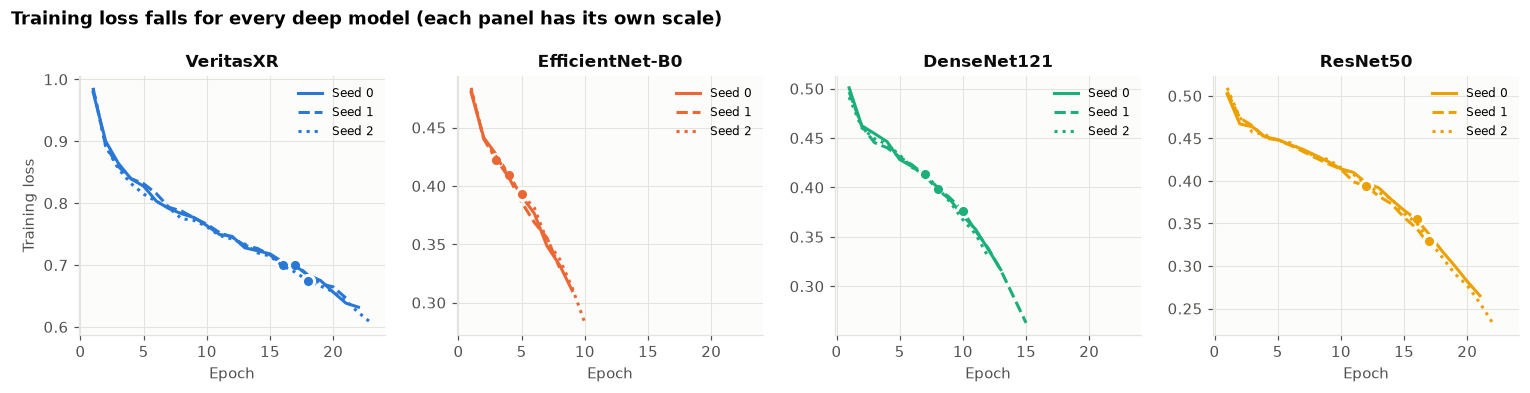

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True)
for ax, m in zip(axes, DEEP):
    for r in get(m):
        h = r["history"]
        ax.plot(h.epoch, h.train_loss, SEED_STYLE[r["seed"]], color=COLOR[m], label=f"Seed {r['seed']}")
        b = h[h.epoch == r["metrics"]["best_epoch"]]
        ax.plot(b.epoch, b.train_loss, "o", ms=8, color=COLOR[m], mec="white", mew=2)
    ax.set_title(MODELS[m]); ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
axes[0].set_ylabel("Training loss")
fig.suptitle("Training loss falls for every deep model (each panel has its own scale)", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

## 3. Validation scores per epoch

These show how each model did on the validation X-rays after each epoch. Higher is better. The rows share a scale, so here you can compare models directly. The sharp rise in DenseNet121 is seed 1 having an unusually poor first epoch, and that one point stretches the scale for the whole row.

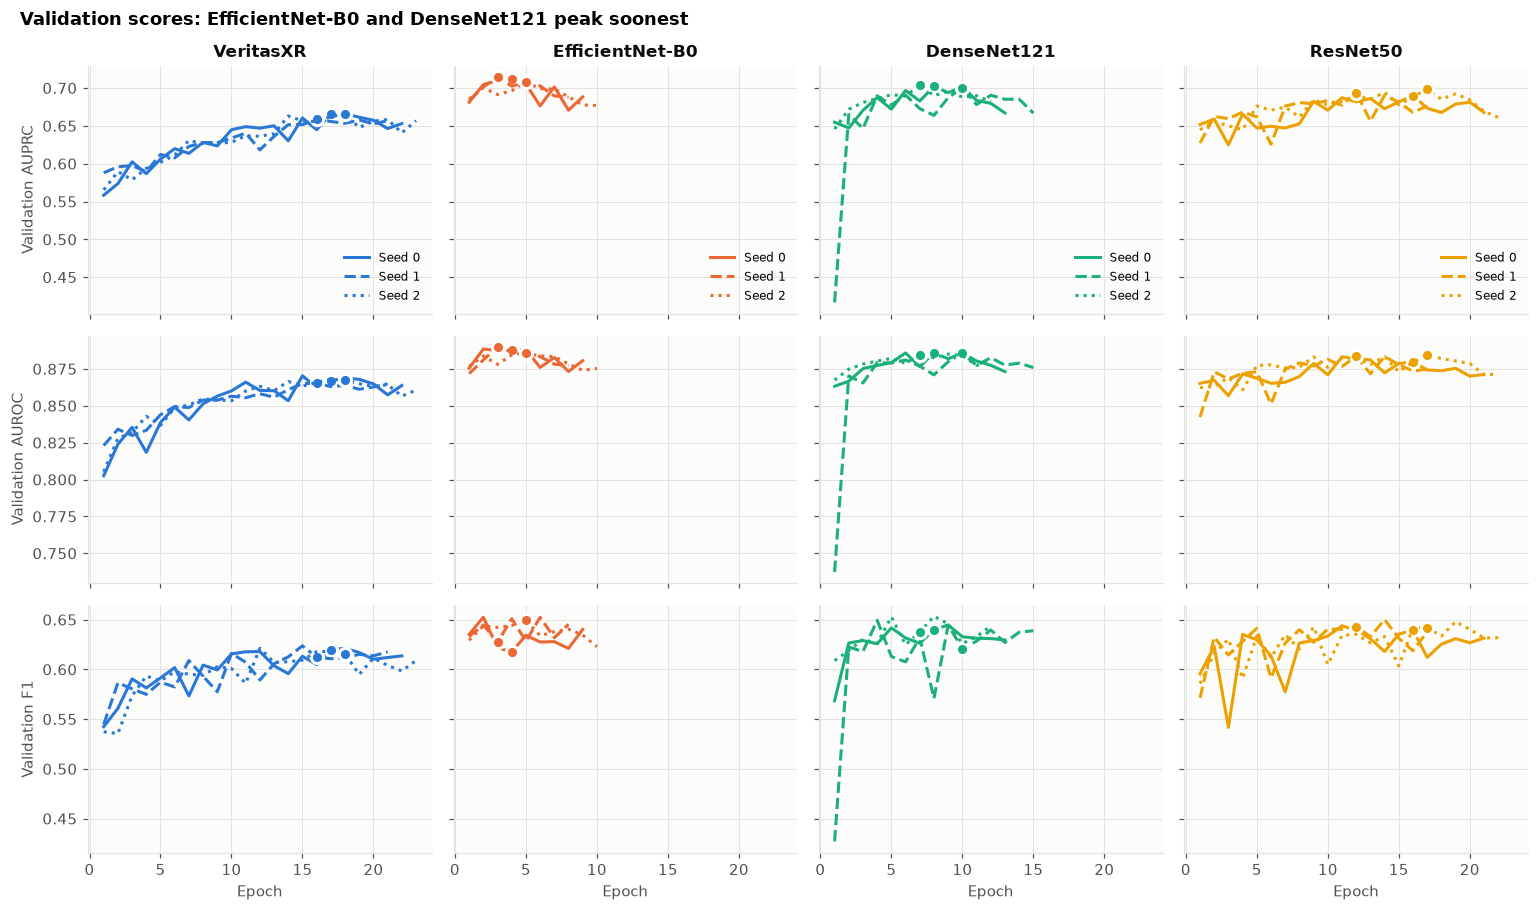

Epochs run  Best epoch  Best validation AUPRC
Model           Run                                                  
VeritasXR       Seed 0          22          17                 0.6661
                Seed 1          21          16                 0.6586
                Seed 2          23          18                 0.6655
EfficientNet-B0 Seed 0           9           4                 0.7113
                Seed 1           8           3                 0.7141
                Seed 2          10           5                 0.7076
DenseNet121     Seed 0          13           8                 0.7022
                Seed 1          15          10                 0.7004
                Seed 2          12           7                 0.7036
ResNet50        Seed 0          21          16                 0.6900
                Seed 1          17          12                 0.6941
                Seed 2          22          17                 0.6987

In [4]:
rows = [("val_auprc", "Validation AUPRC"), ("val_auroc", "Validation AUROC"), ("val_f1", "Validation F1")]
fig, axes = plt.subplots(3, 4, figsize=(14, 8.4), sharex=True, sharey="row")
for i, (k, lab) in enumerate(rows):
    for j, m in enumerate(DEEP):
        ax = axes[i, j]
        for r in get(m):
            h = r["history"]
            ax.plot(h.epoch, h[k], SEED_STYLE[r["seed"]], color=COLOR[m], label=f"Seed {r['seed']}")
            b = h[h.epoch == r["metrics"]["best_epoch"]]
            ax.plot(b.epoch, b[k], "o", ms=8, color=COLOR[m], mec="white", mew=2)
        if i == 0: ax.set_title(MODELS[m]); ax.legend(fontsize=8, loc="lower right")
        if j == 0: ax.set_ylabel(lab)
        if i == 2: ax.set_xlabel("Epoch")
fig.suptitle("Validation scores: EfficientNet-B0 and DenseNet121 peak soonest", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

display(pd.DataFrame([{"Model": MODELS[m], "Run": f"Seed {r['seed']}", "Epochs run": r["metrics"]["epochs_run"],
    "Best epoch": r["metrics"]["best_epoch"], "Best validation AUPRC": round(r["metrics"]["best_val_auprc"], 4)}
    for m in DEEP for r in get(m)]).set_index(["Model", "Run"]))

## 4. Confusion matrices

A confusion matrix counts the four possible outcomes on the test X-rays:

| | Model said no | Model said yes |
|---|---|---|
| **Really negative** | Correctly cleared | False alarm |
| **Really positive** | **Missed case** | Correctly caught |

Numbers are averaged across the 3 runs, so they can be decimals. The percentage is the share of that row: of all the truly positive X-rays, for example, how many were caught. "Positive" means the RSNA lung opacity label (`Target=1`).

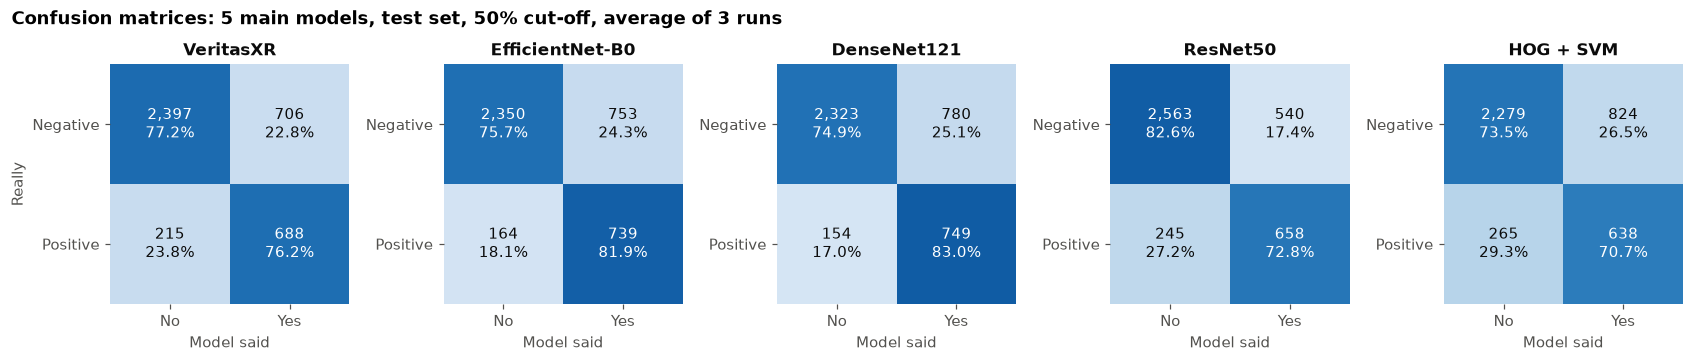

In [5]:
def draw_cm(ax, cm, title):
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap=plt.cm.Blues, vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,.0f}\n{pct[i, j]:.1%}", ha="center", va="center", fontsize=10,
                color="white" if pct[i, j] > .55 else INK)
    ax.set_xticks([0, 1], ["No", "Yes"]); ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Model said"); ax.set_title(title); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def cm_of(r):
    c = r["test"]["confusion"]
    return np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]], float)

def cm_grid(names, labels, ncols, suptitle):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 3.2 * nrows), squeeze=False)
    for ax in axes.flat[len(names):]: ax.axis("off")
    for ax, n in zip(axes.flat, names):
        draw_cm(ax, np.mean([cm_of(r) for r in get(n)], axis=0), labels[n])
    for row in axes: row[0].set_ylabel("Really")
    fig.suptitle(suptitle, x=.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

cm_grid(list(MODELS), MODELS, 5, "Confusion matrices: 5 main models, test set, 50% cut-off, average of 3 runs")

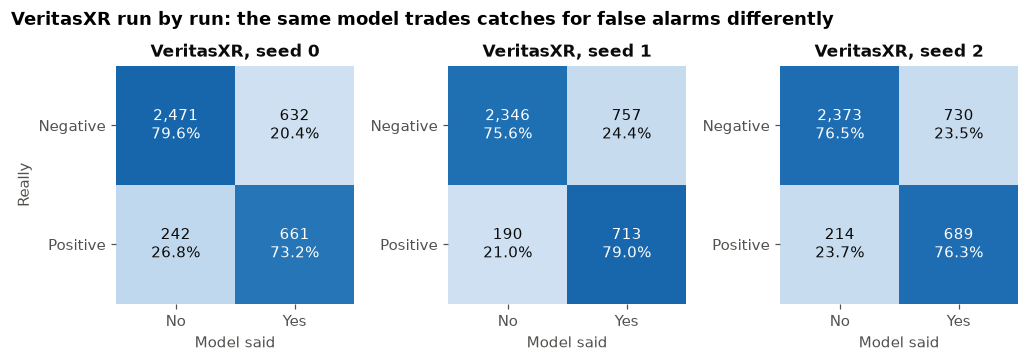

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.2))
for ax, r in zip(axes, get("veritasxr")):
    draw_cm(ax, cm_of(r), f"VeritasXR, seed {r['seed']}")
axes[0].set_ylabel("Really")
fig.suptitle("VeritasXR run by run: the same model trades catches for false alarms differently", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

## 5. Accuracy charts

**Read accuracy with care.** About 77.5% of the test X-rays are negative, so a program that always says "no" scores 77.5% while catching nobody. That's the dashed line below. Balanced accuracy avoids this trap by averaging the catch rate and the clear rate, so the always-"no" program scores 50%.

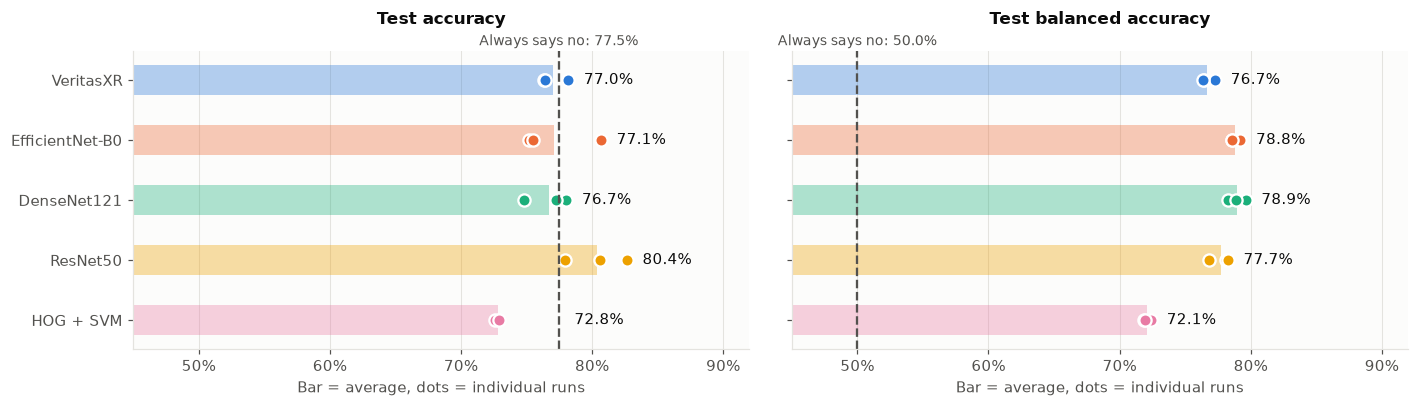

In [ ]:
prev = get("veritasxr")[0]["y_true"].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
order = list(MODELS)[::-1]
for ax, k, title, ref, reflab in [
    (axes[0], "accuracy", "Test accuracy", 1 - prev, f"Always says no: {1 - prev:.1%}"),
    (axes[1], "balanced_accuracy", "Test balanced accuracy", .5, "Always says no: 50.0%")]:
    for y, m in enumerate(order):
        v = np.array([r["test"][k] for r in get(m)])
        ax.barh(y, v.mean(), height=.5, color=COLOR[m], alpha=.35)
        ax.plot(v, [y] * len(v), "o", ms=8, color=COLOR[m], mec="white", mew=1.5)
        ax.text(max(v.max(), ref) + .012, y, f"{v.mean():.1%}", va="center", color=INK)
    ax.axvline(ref, color=MUTED, ls="--", lw=1.5)
    ax.text(ref, len(order) - .42, reflab, color=MUTED, fontsize=9, ha="center")
    ax.set_xlim(.45, .92); ax.set_title(title, pad=18); ax.set_xlabel("Bar = average, dots = individual runs")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), [MODELS[m] for m in order])
fig.tight_layout(); plt.show()

### Accuracy at every cut-off

A model turns its score into a yes or no using a cut-off, normally 50%. This chart shows how test accuracy changes as that cut-off moves. It's for understanding only. The project's tuned cut-offs were chosen on validation data, never from test data like this.

**Why HOG + SVM is flat:** its scores sit almost entirely at the extremes (near 0 or near 1), so moving the cut-off changes almost nothing. That comes from how its scores are converted to 0-1.

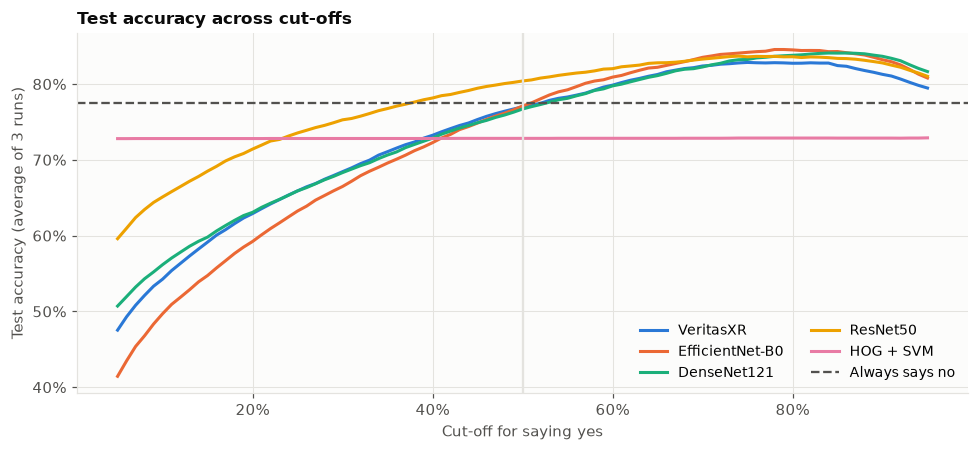

In [8]:
ts = np.linspace(.05, .95, 91)
fig, ax = plt.subplots(figsize=(9, 4.2))
for m in MODELS:
    rs = get(m)
    acc = np.mean([[((r["y_score"] >= t).astype(int) == r["y_true"]).mean() for t in ts] for r in rs], axis=0)
    ax.plot(ts, acc, color=COLOR[m], label=MODELS[m])
ax.axhline(1 - prev, color=MUTED, ls="--", lw=1.5, label="Always says no")
ax.axvline(.5, color=GRID, lw=1.5)
ax.set_xlabel("Cut-off for saying yes"); ax.set_ylabel("Test accuracy (average of 3 runs)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_title("Test accuracy across cut-offs", loc="left"); ax.legend(ncol=2, fontsize=9)
fig.tight_layout(); plt.show()

## 6. VeritasXR versions (ablation)

Each version removes or changes one part of VeritasXR, then is retrained 3 times. `full` is the complete model. Dots show individual runs, so overlapping dots mean the difference may be just run-to-run variation.

,Parameters,Accuracy,Balanced accuracy,AUPRC,AUROC,F1,Caught (sensitivity),Cleared (specificity)
Model,,,,,,,,
Full model,"4,215,352",77.0%,76.7%,0.6410 ± 0.0039,0.8531 ± 0.0028,0.5988,76.2%,77.2%
Concat merge,"4,264,310",77.5%,76.6%,0.6422 ± 0.0060,0.8526 ± 0.0005,0.6000,74.9%,78.2%
Fixed 50/50 merge,"4,166,006",77.2%,76.3%,0.6394 ± 0.0017,0.8531 ± 0.0011,0.5964,74.8%,77.8%
Single global weight,"4,166,008",77.8%,76.5%,0.6360 ± 0.0054,0.8524 ± 0.0008,0.6010,74.0%,79.0%
No SE,"4,177,672",77.3%,76.4%,0.6348 ± 0.0068,0.8504 ± 0.0034,0.5978,74.8%,78.0%
7x7 pathway only,"3,302,108",77.6%,77.0%,0.6337 ± 0.0081,0.8524 ± 0.0047,0.6041,75.9%,78.1%
3x3 pathway only,"1,008,348",75.6%,76.6%,0.6205 ± 0.0131,0.8438 ± 0.0075,0.5912,78.4%,74.7%


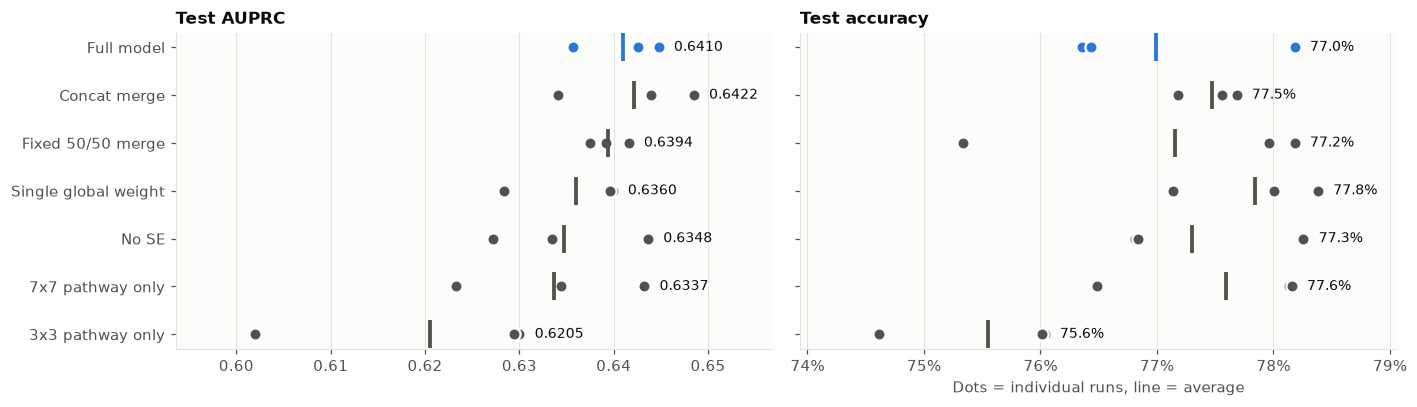

In [9]:
ABL = {"veritasxr_full": "Full model", "veritasxr_concat_merge": "Concat merge", "veritasxr_fixed_merge": "Fixed 50/50 merge",
       "veritasxr_scalar_merge": "Single global weight", "veritasxr_no_se": "No SE", "veritasxr_global_only": "7x7 pathway only",
       "veritasxr_local_only": "3x3 pathway only"}
display(summarise(ABL, ABL))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
names = list(ABL)[::-1]
for ax, k, title, fmt in [(axes[0], "auprc", "Test AUPRC", "{:.4f}"), (axes[1], "accuracy", "Test accuracy", "{:.1%}")]:
    for y, n in enumerate(names):
        v = np.array([r["test"][k] for r in get(n)])
        c_ = COLOR["veritasxr"] if n == "veritasxr_full" else MUTED
        ax.plot(v, [y] * 3, "o", ms=8, color=c_, mec="white", mew=1.5)
        ax.plot(v.mean(), y, "|", ms=18, mew=2.5, color=c_)
        ax.annotate(fmt.format(v.mean()), (v.max(), y), xytext=(10, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False); ax.margins(x=.18)
    if k == "accuracy": ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xlabel("Dots = individual runs, line = average")
axes[0].set_yticks(range(len(names)), [ABL[n] for n in names])
fig.tight_layout(); plt.show()

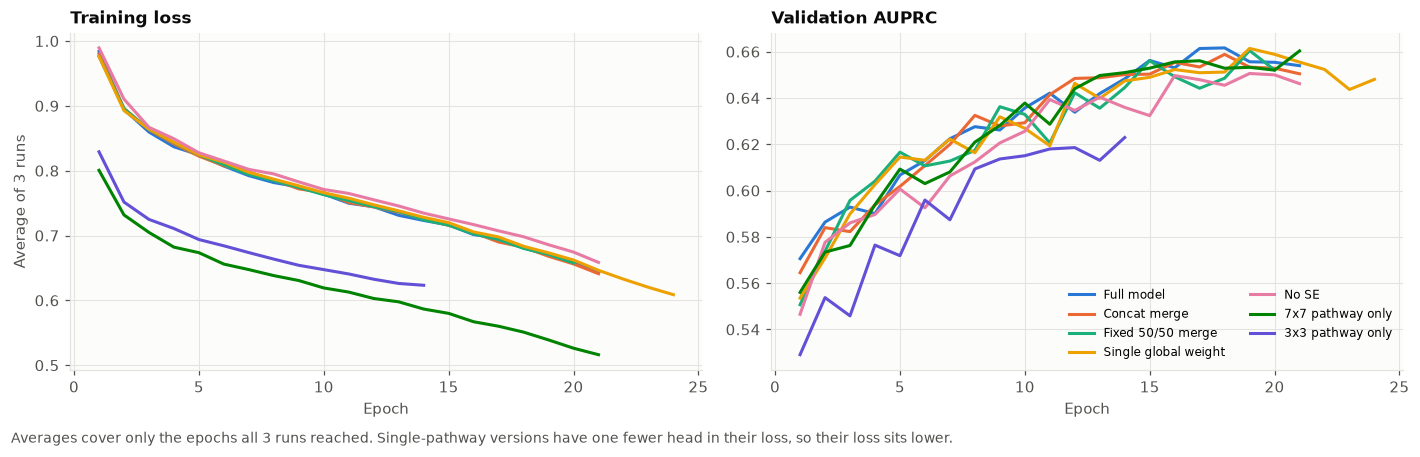

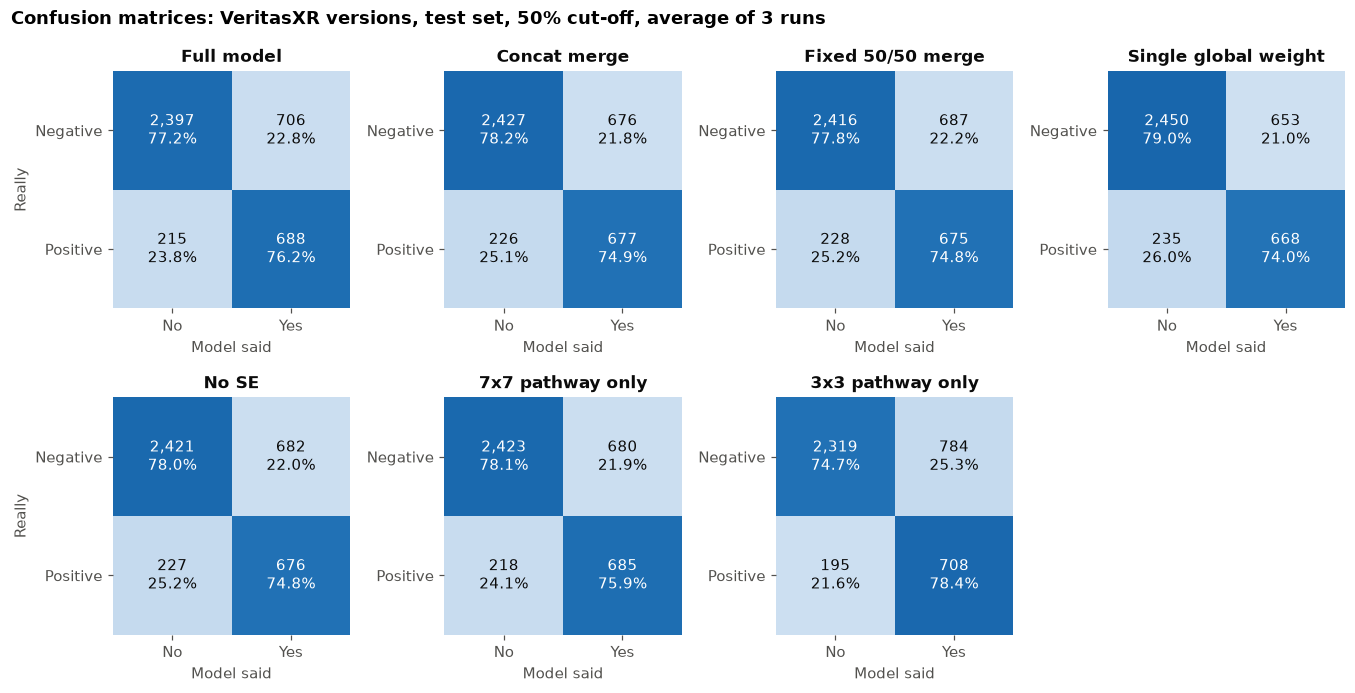

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for i, n in enumerate(ABL):
    color = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#008300","#6250d6"][i]
    h = [r["history"] for r in get(n)]
    L = min(len(x) for x in h)
    for ax, k in zip(axes, ("train_loss", "val_auprc")):
        ax.plot(range(1, L + 1), np.mean([x[k].values[:L] for x in h], axis=0), color=color, label=ABL[n])
axes[0].set_title("Training loss", loc="left"); axes[0].set_ylabel("Average of 3 runs"); axes[0].set_xlabel("Epoch")
axes[1].set_title("Validation AUPRC", loc="left"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8, ncol=2)
fig.text(.01, -.02, "Averages cover only the epochs all 3 runs reached. Single-pathway versions have one fewer head in their loss, so their loss sits lower.", color=MUTED, fontsize=9)
fig.tight_layout(); plt.show()

cm_grid(list(ABL), ABL, 4, "Confusion matrices: VeritasXR versions, test set, 50% cut-off, average of 3 runs")

## 7. Learning-rate tests

Each deep model was also trained at a lower (0.0001) and higher (0.001) learning rate than the shared 0.0003, on seed 0 only, to check the shared setting wasn't unfair.

In [11]:
rows = []
for m in DEEP:
    row = {"Model": MODELS[m]}
    for lab, n in [("0.0001", f"{m}_lr0.0001"), ("0.0003 (shared)", m), ("0.001", f"{m}_lr0.001")]:
        r = [x for x in get(n) if x["seed"] == 0][0]
        row[f"AUPRC @ {lab}"] = round(r["test"]["auprc"], 4); row[f"Accuracy @ {lab}"] = f"{r['test']['accuracy']:.1%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("Model"))

,AUPRC @ 0.0001,Accuracy @ 0.0001,AUPRC @ 0.0003 (shared),Accuracy @ 0.0003 (shared),AUPRC @ 0.001,Accuracy @ 0.001
Model,,,,,,
VeritasXR,0.6316,76.4%,0.6426,78.2%,0.6445,75.4%
EfficientNet-B0,0.6954,72.7%,0.7009,75.2%,0.7025,78.9%
DenseNet121,0.6961,79.2%,0.6824,78.0%,0.6668,80.0%
ResNet50,0.6880,80.7%,0.6849,80.6%,0.6257,79.0%


## 8. Checks

These confirm the charts are drawn from consistent numbers: the saved counts must match the saved per-X-ray scores, and the averages must match the README.

In [12]:
from sklearn.metrics import average_precision_score
for r in runs:
    y, p = r["y_true"], (r["y_score"] >= .5).astype(int)
    c_ = r["test"]["confusion"]
    assert c_ == {"tn": int(((y==0)&(p==0)).sum()), "fp": int(((y==0)&(p==1)).sum()),
                  "fn": int(((y==1)&(p==0)).sum()), "tp": int(((y==1)&(p==1)).sum())}, r["name"]
    assert abs(average_precision_score(y, r["y_score"]) - r["test"]["auprc"]) < 1e-9, r["name"]
    assert sum(c_.values()) == 4006, r["name"]
README = {"efficientnet_b0": .6993, "densenet121": .6872, "resnet50": .6747, "veritasxr": .6410, "hog_svm": .3823}
for m, want in README.items():
    got = np.mean([r["test"]["auprc"] for r in get(m)])
    assert abs(got - want) < 6e-5, (m, got, want)
print(f"All {len(runs)} runs: confusion counts and AUPRC match the saved scores; main AUPRC averages match the README.")

All 44 runs: confusion counts and AUPRC match the saved scores; main AUPRC averages match the README.
